In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import ml_edu.experiment
import ml_edu.results
import keras

In [2]:
chicago_taxi_dataset = pd.read_csv("https://download.mlcc.google.com/mledu-datasets/chicago_taxi_train.csv")

In [3]:
training_df = chicago_taxi_dataset.loc[:, ('TRIP_MILES', 'TRIP_SECONDS', 'FARE', 'COMPANY', 'PAYMENT_TYPE', 'TIP_RATE')]

print('Read dataset completed successfully.')
print('Total number of rows: {0}\n\n'.format(len(training_df.index)))
training_df.head(200)

Read dataset completed successfully.
Total number of rows: 31694




,TRIP_MILES,TRIP_SECONDS,FARE,COMPANY,PAYMENT_TYPE,TIP_RATE
0,2.57,2341,31.99,Flash Cab,Mobile,6.3
1,1.18,1074,9.75,Flash Cab,Credit Card,27.9
2,1.29,1173,10.25,Sun Taxi,Cash,0.0
3,3.70,3360,23.75,Choice Taxi Association,Cash,0.0
4,1.15,1044,10.00,Flash Cab,Cash,0.0
...,...,...,...,...,...,...
195,1.13,821,9.00,Blue Ribbon Taxi Association,Mobile,22.9
196,0.57,414,6.00,Flash Cab,Cash,0.0
197,1.22,886,9.00,City Service,Cash,0.0
198,1.68,1219,9.00,Sun Taxi,Mobile,23.0


In [4]:
training_df.describe(include='all')

,TRIP_MILES,TRIP_SECONDS,FARE,COMPANY,PAYMENT_TYPE,TIP_RATE
count,31694.000000,31694.000000,31694.000000,31694,31694,31694.000000
unique,NaN,NaN,NaN,31,7,NaN
top,NaN,NaN,NaN,Flash Cab,Credit Card,NaN
freq,NaN,NaN,NaN,7887,14142,NaN
mean,8.289463,1319.796397,23.905210,NaN,NaN,12.965785
std,7.265672,928.932873,16.970022,NaN,NaN,15.517765
min,0.500000,60.000000,3.250000,NaN,NaN,0.000000
25%,1.720000,548.000000,9.000000,NaN,NaN,0.000000
50%,5.920000,1081.000000,18.750000,NaN,NaN,12.200000
75%,14.500000,1888.000000,38.750000,NaN,NaN,20.800000


In [5]:
training_df.corr(numeric_only = True)

,TRIP_MILES,TRIP_SECONDS,FARE,TIP_RATE
TRIP_MILES,1.000000,0.800855,0.975344,-0.049594
TRIP_SECONDS,0.800855,1.000000,0.830292,-0.084294
FARE,0.975344,0.830292,1.000000,-0.070979
TIP_RATE,-0.049594,-0.084294,-0.070979,1.000000


In [6]:
px.scatter_matrix(training_df, dimensions=["FARE", "TRIP_MILES", "TRIP_SECONDS"])

In [7]:
def create_model(
    settings: ml_edu.experiment.ExperimentSettings,
    metrics: list[keras.metrics.Metric],
) -> keras.Model:
  """Create and compile a simple linear regression model."""
  # Describe the topography of the model.
  # The topography of a simple linear regression model
  # is a single node in a single layer.
  inputs = {name: keras.Input(shape=(1,), name=name) for name in settings.input_features}
  concatenated_inputs = keras.layers.Concatenate()(list(inputs.values()))
  outputs = keras.layers.Dense(units=1)(concatenated_inputs)
  model = keras.Model(inputs=inputs, outputs=outputs)

  # Compile the model topography into code that Keras can efficiently
  # execute. Configure training to minimize the model's mean squared error.
  model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=settings.learning_rate),
                loss="mean_squared_error",
                metrics=metrics)

  return model


def train_model(
    experiment_name: str,
    model: keras.Model,
    dataset: pd.DataFrame,
    label_name: str,
    settings: ml_edu.experiment.ExperimentSettings,
) -> ml_edu.experiment.Experiment:
  """Train the model by feeding it data."""

  # Feed the model the feature and the label.
  # The model will train for the specified number of epochs.
  features = {name: dataset[name].values for name in settings.input_features}
  label = dataset[label_name].values
  history = model.fit(x=features,
                      y=label,
                      batch_size=settings.batch_size,
                      epochs=settings.number_epochs)

  return ml_edu.experiment.Experiment(
      name=experiment_name,
      settings=settings,
      model=model,
      epochs=history.epoch,
      metrics_history=pd.DataFrame(history.history),
  )

print("SUCCESS: defining linear regression functions complete.")

SUCCESS: defining linear regression functions complete.


Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 882us/step - loss: 553.1000 - rmse: 23.5181
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 730us/step - loss: 269.5958 - rmse: 16.4194
Epoch 3/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 758us/step - loss: 93.8343 - rmse: 9.6868 
Epoch 4/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 22.7490 - rmse: 4.7696  
Epoch 5/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 742us/step - loss: 16.2779 - rmse: 4.0346
Epoch 6/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 742us/step - loss: 15.3632 - rmse: 3.9196
Epoch 7/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 745us/step - loss: 14.7342 - rmse: 3.8385
Epoch 8/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 763us/step - loss: 14.3707 - rmse: 3.7909
Epoch 9/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 743us/step - loss: 14.1873 - rmse: 3.7666
Epoch 10/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 750us/step - loss: 14.1005 - rmse: 3.7551
Epoch 11/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 922us/step - loss: 14.0569 - rmse: 3.7493
Epoch 12/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 864us/step - l

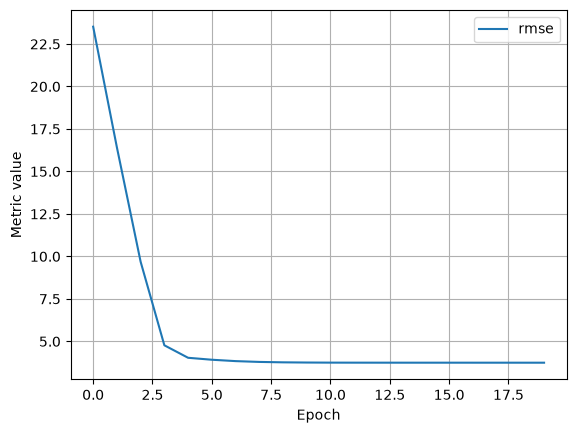

In [15]:
settings_1 = ml_edu.experiment.ExperimentSettings(
    learning_rate = 0.001,
    number_epochs = 20,
    batch_size = 50,
    input_features = ['TRIP_MILES']
)

metrics = [keras.metrics.RootMeanSquaredError(name='rmse')]

model_1 = create_model(settings_1, metrics)

experiment_1 = train_model('one_feature', model_1, training_df, 'FARE', settings_1)

ml_edu.results.plot_experiment_metrics(experiment_1, ['rmse'])
ml_edu.results.plot_model_predictions(experiment_1, training_df, 'FARE')

Epoch 1/50
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 324.9511 - rmse: 18.0264
Epoch 2/50
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 904us/step - loss: 299.7867 - rmse: 17.3144
Epoch 3/50
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 751us/step - loss: 275.7973 - rmse: 16.6071
Epoch 4/50
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 741us/step - loss: 252.8263 - rmse: 15.9005
Epoch 5/50
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 766us/step - loss: 230.9105 - rmse: 15.1957
Epoch 6/50
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 752us/step - loss: 210.1406 - rmse: 14.4962
Epoch 7/50
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 761us/step - loss: 190.3165 - rmse: 13.7955
Epoch 8/50
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 755us/step - loss: 171.6787 - rmse: 13.1026
Epoch 9/50
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 859us/step - loss: 154.1361 - rmse: 12.4152
Epoch 10/50
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 759us/step - loss: 137.5509 - rmse: 11.7282
Epoch 11/50
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 755us/step - loss: 122.1801 - rmse: 11.0535
Epoch 12/50
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s

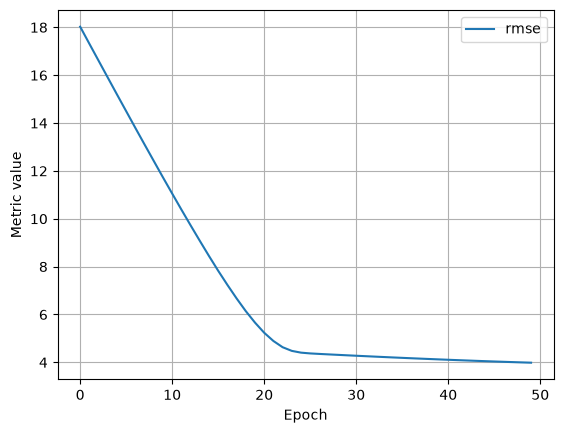

In [19]:

# The following variables are the hyperparameters.
# TODO - Adjust these hyperparameters to see how they impact a training run.
settings_2 = ml_edu.experiment.ExperimentSettings(
    learning_rate = 0.0001,
    number_epochs = 50,
    batch_size = 50,
    input_features = ['TRIP_MILES']
)

metrics = [keras.metrics.RootMeanSquaredError(name='rmse')]

model_2 = create_model(settings_2, metrics)

experiment_2 = train_model('one_feature_hyper', model_2, training_df, 'FARE', settings_2)

ml_edu.results.plot_experiment_metrics(experiment_2, ['rmse'])
ml_edu.results.plot_model_predictions(experiment_2, training_df, 'FARE')

Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 807us/step - loss: 74.7111 - rmse: 8.6436
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 829us/step - loss: 42.0606 - rmse: 6.4854
Epoch 3/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 959us/step - loss: 25.8666 - rmse: 5.0859
Epoch 4/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 851us/step - loss: 17.3549 - rmse: 4.1659
Epoch 5/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 867us/step - loss: 14.2220 - rmse: 3.7712
Epoch 6/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 845us/step - loss: 13.1916 - rmse: 3.6320
Epoch 7/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 805us/step - loss: 12.6882 - rmse: 3.5620
Epoch 8/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 856us/step - loss: 12.3961 - rmse: 3.5208
Epoch 9/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 890us/step - loss: 12.2501 - rmse: 3.5000
Epoch 10/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 768us/step - loss: 12.1646 - rmse: 3.4878
Epoch 11/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 756us/step - loss: 12.1254 - rmse: 3.4822
Epoch 12/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 759us/step - loss: 

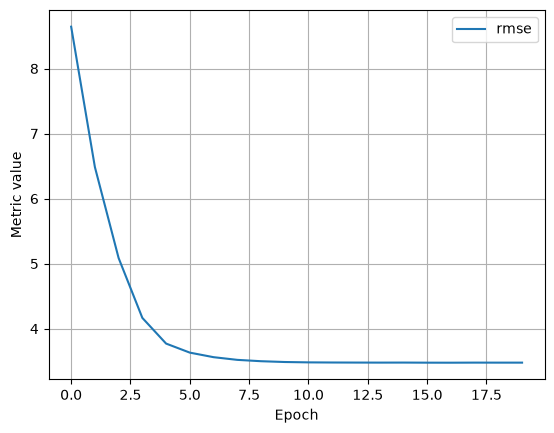

In [20]:
settings_3 = ml_edu.experiment.ExperimentSettings(
    learning_rate = 0.001,
    number_epochs = 20,
    batch_size = 50,
    input_features = ['TRIP_MILES', 'TRIP_MINUTES']
)

training_df['TRIP_MINUTES'] = training_df['TRIP_SECONDS']/60

metrics = [keras.metrics.RootMeanSquaredError(name='rmse')]

model_3 = create_model(settings_3, metrics)

experiment_3 = train_model('two_features', model_3, training_df, 'FARE', settings_3)

ml_edu.results.plot_experiment_metrics(experiment_3, ['rmse'])
ml_edu.results.plot_model_predictions(experiment_3, training_df, 'FARE')

Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 18669.0254 - rmse: 136.6346  
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 811us/step - loss: 50.6346 - rmse: 7.1158
Epoch 3/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 784us/step - loss: 31.2238 - rmse: 5.5878
Epoch 4/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 774us/step - loss: 20.4472 - rmse: 4.5219
Epoch 5/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 769us/step - loss: 15.9148 - rmse: 3.9893
Epoch 6/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 835us/step - loss: 14.6180 - rmse: 3.8233
Epoch 7/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 837us/step - loss: 14.0222 - rmse: 3.7446
Epoch 8/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 805us/step - loss: 13.6563 - rmse: 3.6954
Epoch 9/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 808us/step - loss: 13.4586 - rmse: 3.6686
Epoch 10/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 880us/step - loss: 13.2726 - rmse: 3.6432
Epoch 11/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 929us/step - loss: 13.1950 - rmse: 3.6325
Epoch 12/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 800us/step - l

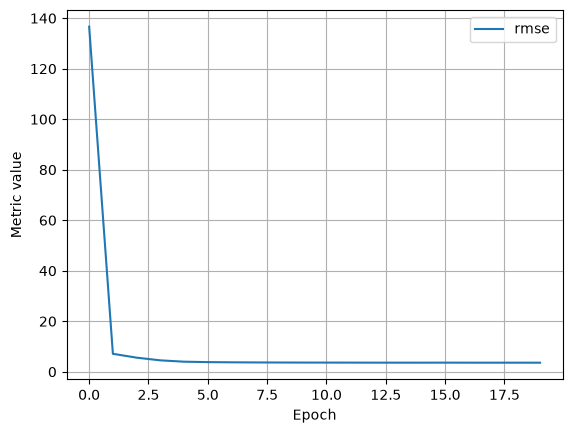

In [21]:
settings_3 = ml_edu.experiment.ExperimentSettings(
    learning_rate = 0.001,
    number_epochs = 20,
    batch_size = 50,
    input_features = ['TRIP_MILES', 'TRIP_SECONDS']
)

# training_df['TRIP_MINUTES'] = training_df['TRIP_SECONDS']/60

metrics = [keras.metrics.RootMeanSquaredError(name='rmse')]

model_3 = create_model(settings_3, metrics)

experiment_3 = train_model('two_features', model_3, training_df, 'FARE', settings_3)

ml_edu.results.plot_experiment_metrics(experiment_3, ['rmse'])
ml_edu.results.plot_model_predictions(experiment_3, training_df, 'FARE')

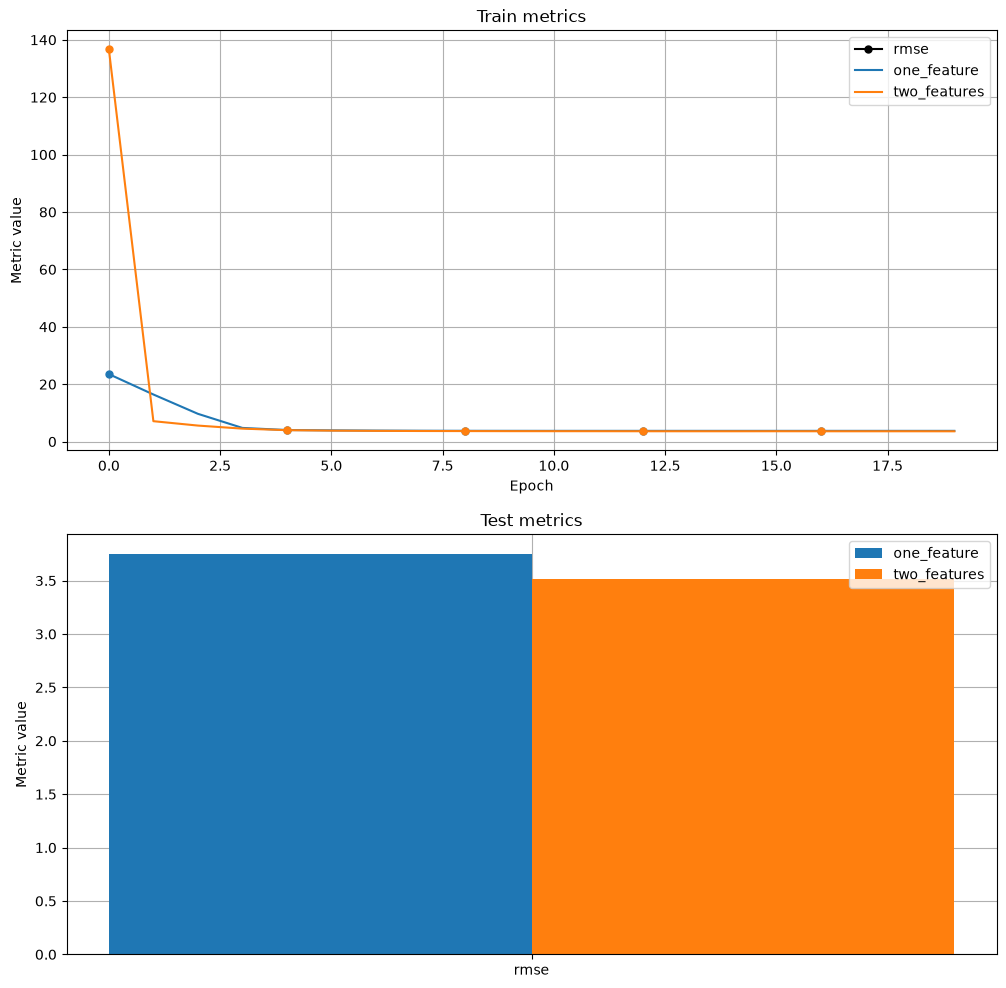

In [22]:
ml_edu.results.compare_experiment([experiment_1, experiment_3], ['rmse'], training_df, training_df['FARE'].values)

In [23]:
def format_currency(x):
  return "${:.2f}".format(x)

def build_batch(df, batch_size):
  batch = df.sample(n=batch_size).copy()
  batch.set_index(np.arange(batch_size), inplace=True)
  return batch

def predict_fare(model, df, features, label, batch_size=50):
  batch = build_batch(df, batch_size)
  predicted_values = model.predict_on_batch(x={name: batch[name].values for name in features})

  data = {"PREDICTED_FARE": [], "OBSERVED_FARE": [], "L1_LOSS": [],
          features[0]: [], features[1]: []}
  for i in range(batch_size):
    predicted = predicted_values[i][0]
    observed = batch.at[i, label]
    data["PREDICTED_FARE"].append(format_currency(predicted))
    data["OBSERVED_FARE"].append(format_currency(observed))
    data["L1_LOSS"].append(format_currency(abs(observed - predicted)))
    data[features[0]].append(batch.at[i, features[0]])
    data[features[1]].append("{:.2f}".format(batch.at[i, features[1]]))

  output_df = pd.DataFrame(data)
  return output_df

def show_predictions(output):
  header = "-" * 80
  banner = header + "\n" + "|" + "PREDICTIONS".center(78) + "|" + "\n" + header
  print(banner)
  print(output)
  return

In [24]:
output = predict_fare(experiment_3.model, training_df, experiment_3.settings.input_features, 'FARE')
show_predictions(output)

--------------------------------------------------------------------------------
|                                 PREDICTIONS                                  |
--------------------------------------------------------------------------------
   PREDICTED_FARE OBSERVED_FARE L1_LOSS  TRIP_MILES TRIP_SECONDS
0          $21.75        $21.75   $0.00        7.81       991.00
1          $17.93        $17.25   $0.68        6.19       747.00
2          $46.02        $44.50   $1.52       17.75      2874.00
3          $38.55        $38.75   $0.20       13.40      3480.00
4           $7.62         $8.00   $0.38        1.22       634.00
5           $5.65         $5.25   $0.40        0.63       282.00
6          $13.87        $13.75   $0.12        4.52       440.00
7          $12.57        $12.00   $0.57        3.70       600.00
8          $37.76        $37.25   $0.51       13.77      2782.00
9          $14.79        $14.75   $0.04        4.80       600.00
10         $47.57        $47.75   $0.18   